In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import check_array, check_is_fitted

SEED = 42
TARGET = "Target_local_recurrence"
pd.set_option("display.max_columns", None)
print(f"numpy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}")

numpy 2.5.3; pandas 3.0.6; scikit-learn 1.9.1


In [2]:
analytic = pd.read_csv("../w4/analytic_table.csv")
test_membership = pd.read_csv("../w5/test.csv", usecols=["Patient_ID", TARGET])
previous_train_ids = pd.read_csv("../w5/train.csv", usecols=["Patient_ID"])["Patient_ID"]
assert analytic.Patient_ID.is_unique and test_membership.Patient_ID.is_unique
assert set(previous_train_ids).isdisjoint(test_membership.Patient_ID)
assert set(previous_train_ids) | set(test_membership.Patient_ID) == set(analytic.Patient_ID)
assert analytic.set_index("Patient_ID").loc[test_membership.Patient_ID, TARGET].tolist() == test_membership[TARGET].tolist()

pool = analytic.loc[analytic.Patient_ID.isin(previous_train_ids)].copy()
train, validation = train_test_split(pool, test_size=0.2, stratify=pool[TARGET], random_state=SEED)
train = train.sort_values("Patient_ID").reset_index(drop=True)
validation = validation.sort_values("Patient_ID").reset_index(drop=True)
assert set(train.Patient_ID).isdisjoint(validation.Patient_ID)
assert set(train.Patient_ID) | set(validation.Patient_ID) == set(previous_train_ids)
repeat_train, repeat_validation = train_test_split(pool, test_size=0.2, stratify=pool[TARGET], random_state=SEED)
assert set(repeat_train.Patient_ID) == set(train.Patient_ID)
assert set(repeat_validation.Patient_ID) == set(validation.Patient_ID)

samples = {"Обучение": train, "Валидация": validation, "Тест (отложен)": test_membership}
display(pd.DataFrame({name: {"Пациентов": len(frame), "Исход 1": int(frame[TARGET].sum())}
                      for name, frame in samples.items()}).T)
for name, frame in samples.items():
    print(f"{name}: {sorted(frame.Patient_ID.tolist())}")

,Пациентов,Исход 1
Обучение,84,7
Валидация,21,2
Тест (отложен),35,3


Обучение: [1, 7, 8, 9, 10, 11, 13, 15, 19, 20, 22, 23, 25, 26, 27, 32, 35, 37, 42, 46, 49, 51, 52, 54, 57, 58, 59, 60, 61, 62, 63, 65, 66, 67, 68, 72, 73, 74, 75, 78, 79, 83, 84, 86, 87, 91, 93, 94, 97, 98, 101, 102, 104, 105, 108, 109, 111, 115, 116, 117, 118, 121, 122, 124, 125, 131, 132, 133, 137, 138, 144, 146, 150, 159, 169, 178, 179, 194, 196, 276, 285, 293, 302, 312]
Валидация: [5, 6, 12, 24, 38, 41, 43, 45, 56, 64, 89, 90, 103, 106, 120, 123, 141, 143, 154, 158, 273]
Тест (отложен): [2, 4, 21, 29, 31, 34, 39, 44, 47, 48, 55, 69, 70, 77, 80, 82, 85, 95, 99, 100, 107, 113, 114, 119, 128, 135, 136, 139, 140, 142, 152, 156, 170, 174, 313]


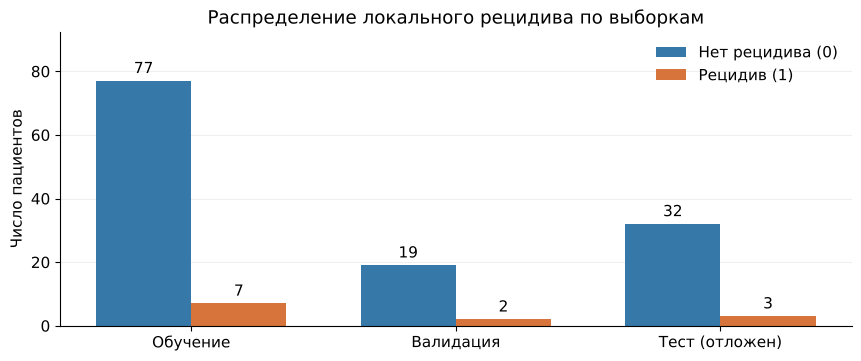

In [3]:
split_names = ["Обучение", "Валидация", "Тест (отложен)"]
counts = pd.DataFrame({name: frame[TARGET].value_counts().reindex([0, 1], fill_value=0)
                       for name, frame in samples.items()}).T.loc[split_names]
colors = ["#3678A8", "#D7743B"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
x = np.arange(len(counts))
for outcome, label, color, offset in [(0, "Нет рецидива (0)", colors[0], -0.18),
                                      (1, "Рецидив (1)", colors[1], 0.18)]:
    bars = ax.bar(x + offset, counts[outcome], width=0.36, label=label, color=color)
    ax.bar_label(bars, padding=3)
ax.set(title="Распределение локального рецидива по выборкам", ylabel="Число пациентов",
       xticks=x, xticklabels=split_names, ylim=(0, counts.to_numpy().max() * 1.2))
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
fig.savefig("text/fig/target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

fig.set_size_inches(4.8, 3.1)
ax.set_title("")
ax.set_xticks(x, ["Обучение", "Валидация", "Тест"])
ax.legend(frameon=False, fontsize=10)
fig.savefig("text/fig/target_distribution_report.pdf", bbox_inches="tight")

In [4]:
binary = ["Gender", "Induction_Chemotherapy", "Concurrent_chemotherapy"]
ordinal = ["T_category", "N_category", "AJCC_Stage", "Pathological_grade"]
nominal = ["Race", "Tumor_side", "Tumor_subsite", "Smoking_status_at_diagnosis"]
quantitative = [col for col in pool if col not in ["Patient_ID", TARGET] + binary + ordinal + nominal]
features = quantitative + ordinal + binary + nominal
X_train, y_train = train[features], train[TARGET]
X_validation, y_validation = validation[features], validation[TARGET]
assert len(features) == 31 and len(quantitative) == 20

ordinal_codes = {
    "T_category": {1: 1, 2: 2, 3: 3, 4: 4},
    "N_category": {"0": 0, "1": 1, "2a": 2, "2b": 3, "2c": 4, "3": 5},
    "AJCC_Stage": {"I": 1, "II": 2, "III": 3, "IV": 4},
    "Pathological_grade": {"I": 1, "I-II": 1.5, "II": 2, "II-III": 2.5, "III": 3, "IV": 4},
}
binary_codes = {"Gender": {"Female": 0, "Male": 1},
                "Induction_Chemotherapy": {"N": 0, "Y": 1},
                "Concurrent_chemotherapy": {"N": 0, "Y": 1}}

def encode_ordinal(frame):
    return pd.DataFrame({col: frame[col].map(ordinal_codes[col]) for col in frame}, index=frame.index)

def encode_binary(frame):
    return pd.DataFrame({col: frame[col].map(binary_codes[col]) for col in frame}, index=frame.index)

def grade_missing(frame):
    return frame.isna().astype(float)

class OutlierAwareScaler(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        values = check_array(X, dtype=float)
        self.n_features_in_ = values.shape[1]
        self.n_samples_seen_ = values.shape[0]
        q1, q3 = np.quantile(values, [0.25, 0.75], axis=0)
        iqr = q3 - q1
        self.outlier_counts_ = ((values < q1 - 1.5 * iqr)
                               | (values > q3 + 1.5 * iqr)).sum(axis=0)
        self.robust_mask_ = self.outlier_counts_ > 0
        if np.any(iqr[self.robust_mask_] <= 0):
            raise ValueError("Нулевой межквартильный размах у признака с выбросами")
        standard = StandardScaler().fit(values)
        self.center_ = np.where(self.robust_mask_, np.median(values, axis=0), standard.mean_)
        self.scale_ = np.where(self.robust_mask_, iqr, standard.scale_)
        return self

    def transform(self, X):
        check_is_fitted(self, ["center_", "scale_"])
        values = check_array(X, dtype=float)
        if values.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков не совпадает с обучающей выборкой")
        return (values - self.center_) / self.scale_


numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
quantitative_preparation = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", OutlierAwareScaler()),
])
preparation = ColumnTransformer([
    ("quantitative", quantitative_preparation, quantitative),
    ("ordinal", Pipeline([
        ("encode", FunctionTransformer(encode_ordinal, feature_names_out="one-to-one")),
        ("numeric", clone(numeric)),
    ]), ordinal),
    ("binary", Pipeline([
        ("encode", FunctionTransformer(encode_binary, feature_names_out="one-to-one")),
        ("impute", SimpleImputer(strategy="most_frequent")),
    ]), binary),
    ("nominal", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(min_frequency=5, drop="first", handle_unknown="infrequent_if_exist", sparse_output=False)),
    ]), nominal),
    ("grade_missing", FunctionTransformer(grade_missing, feature_names_out="one-to-one"), ["Pathological_grade"]),
], remainder="drop")

display(pd.DataFrame({"Группа": ["Количественные", "Порядковые", "Бинарные", "Номинальные"],
                      "Число исходных признаков": [len(quantitative), len(ordinal), len(binary), len(nominal)]}))

,Группа,Число исходных признаков
0,Количественные,20
1,Порядковые,4
2,Бинарные,3
3,Номинальные,4


In [5]:
classifiers = {
    "Логистическая регрессия": LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000, random_state=SEED),
    "Дерево решений": DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, class_weight="balanced", random_state=SEED),
    "Случайный лес": RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=5,
                                             max_features="sqrt", class_weight="balanced_subsample",
                                             random_state=SEED, n_jobs=2),
}
parameter_names = ["C", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight", "random_state"]
display(pd.DataFrame({name: {key: model.get_params().get(key, "—") for key in parameter_names}
                      for name, model in classifiers.items()}).T)
models = {}
rows = []
for name, classifier in classifiers.items():
    model = Pipeline([("prepare", clone(preparation)), ("classifier", clone(classifier))])
    model.fit(X_train, y_train)
    models[name] = model
    fitted = model.named_steps["prepare"]
    q = fitted.named_transformers_["quantitative"]
    assert np.allclose(q.named_steps["impute"].statistics_, X_train[quantitative].median().to_numpy())
    assert int(q.named_steps["scale"].n_samples_seen_) == len(train)
    transformed = fitted.transform(X_validation)
    assert np.isfinite(transformed).all()
    rows.append({"Модель": name, "Обучающих пациентов": len(train), "Подготовленных признаков": transformed.shape[1]})
display(pd.DataFrame(rows).set_index("Модель"))

scaling = next(iter(models.values())).named_steps["prepare"].named_transformers_["quantitative"]
imputed_train = scaling.named_steps["impute"].transform(X_train[quantitative])
fitted_scaler = scaling.named_steps["scale"]
scaled_train = fitted_scaler.transform(imputed_train)
robust_mask = fitted_scaler.robust_mask_
assert np.allclose(np.median(scaled_train[:, robust_mask], axis=0), 0, atol=1e-10)
assert np.allclose(np.quantile(scaled_train[:, robust_mask], 0.75, axis=0)
                   - np.quantile(scaled_train[:, robust_mask], 0.25, axis=0), 1, atol=1e-10)
assert np.allclose(scaled_train[:, ~robust_mask].mean(axis=0), 0, atol=1e-10)
assert np.allclose(scaled_train[:, ~robust_mask].std(axis=0), 1, atol=1e-10)
for model in models.values():
    scaler = model.named_steps["prepare"].named_transformers_["quantitative"].named_steps["scale"]
    assert np.array_equal(scaler.robust_mask_, robust_mask)
    assert np.allclose(scaler.center_, fitted_scaler.center_)
    assert np.allclose(scaler.scale_, fitted_scaler.scale_)
normalization = pd.DataFrame({
    "Выбросов на обучении": fitted_scaler.outlier_counts_,
    "Нормализация": np.where(robust_mask, "медиана / IQR", "среднее / std"),
    "Центр": fitted_scaler.center_,
    "Масштаб": fitted_scaler.scale_,
}, index=quantitative)
print(f"Количественные признаки: медиана / IQR — {int(robust_mask.sum())}, среднее / std — {int((~robust_mask).sum())}.")
display(normalization.round(4))

,C,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,random_state
Логистическая регрессия,0.1,—,—,—,—,balanced,42
Дерево решений,—,—,3,8,None,balanced,42
Случайный лес,—,300,3,5,sqrt,balanced_subsample,42


,Обучающих пациентов,Подготовленных признаков
Модель,,
Логистическая регрессия,84,36
Дерево решений,84,36
Случайный лес,84,36


Количественные признаки: медиана / IQR — 15, среднее / std — 5.


,Выбросов на обучении,Нормализация,Центр,Масштаб
Age_at_diagnosis,0,среднее / std,59.2500,8.6903
Smoking_Pack-Years,2,медиана / IQR,14.5000,30.0000
Total_prescribed_Radiation_treatment_dose,0,среднее / std,68.4762,2.4028
Dose_per_fraction,15,медиана / IQR,2.1212,0.0788
GTVp_shape_MeshVolume,8,медиана / IQR,8000.9167,9910.5833
GTVp_shape_Sphericity,0,среднее / std,0.6166,0.1022
GTVp_shape_Elongation,2,медиана / IQR,0.7418,0.1810
GTVp_shape_Flatness,1,медиана / IQR,0.5447,0.1854
GTVp_firstorder_10Percentile,5,медиана / IQR,55.0000,28.2500
GTVp_firstorder_90Percentile,4,медиана / IQR,111.0000,20.2500


In [6]:
from pathlib import Path

fitted_preparation = models["Логистическая регрессия"].named_steps["prepare"]
Path("prepared").mkdir(exist_ok=True)
for split, frame in [("train", train), ("validation", validation)]:
    prepared = pd.DataFrame(fitted_preparation.transform(frame[features]),
                            columns=fitted_preparation.get_feature_names_out())
    prepared.insert(0, "Patient_ID", frame.Patient_ID)
    prepared.insert(1, TARGET, frame[TARGET])
    prepared.to_csv(f"prepared/{split}.csv", index=False)
    print(f"prepared/{split}.csv: {prepared.shape[0]} пациентов, {prepared.shape[1] - 2} признаков; "
          f"подготовка настроена на {len(train)} обучающих пациентах")

prepared/train.csv: 84 пациентов, 36 признаков; подготовка настроена на 84 обучающих пациентах
prepared/validation.csv: 21 пациентов, 36 признаков; подготовка настроена на 84 обучающих пациентах


In [7]:
baseline = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train), 1)), y_train)
train_predictions = {name: model.predict(X_train) for name, model in models.items()}
validation_predictions = {name: model.predict(X_validation) for name, model in models.items()}
train_predictions["Всегда нет рецидива (ориентир)"] = baseline.predict(np.zeros((len(train), 1)))
validation_predictions["Всегда нет рецидива (ориентир)"] = baseline.predict(np.zeros((len(validation), 1)))

comparison = pd.DataFrame([
    {"Модель": name,
     "Accuracy: обучение": accuracy_score(y_train, train_predictions[name]),
     "Accuracy: валидация": accuracy_score(y_validation, validation_predictions[name]),
     "Balanced accuracy: валидация": balanced_accuracy_score(y_validation, validation_predictions[name]),
     "Чувствительность: валидация": recall_score(y_validation, validation_predictions[name], zero_division=0)}
    for name in validation_predictions
]).set_index("Модель")
display(comparison.round(4))

,Accuracy: обучение,Accuracy: валидация,Balanced accuracy: валидация,Чувствительность: валидация
Модель,,,,
Логистическая регрессия,0.9048,0.7619,0.4211,0.0
Дерево решений,0.9524,0.8095,0.4474,0.0
Случайный лес,1.0000,0.9048,0.5000,0.0
Всегда нет рецидива (ориентир),0.9167,0.9048,0.5000,0.0


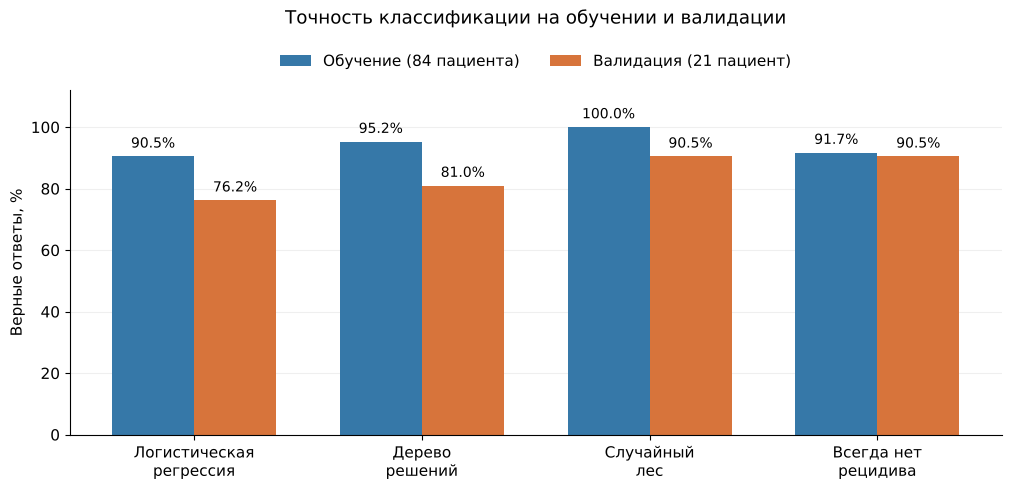

In [8]:
plot_labels = ["Логистическая\nрегрессия", "Дерево\nрешений", "Случайный\nлес", "Всегда нет\nрецидива"]
x = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
for column, label, color, offset in [("Accuracy: обучение", "Обучение (84 пациента)", "#3678A8", -0.18),
                                      ("Accuracy: валидация", "Валидация (21 пациент)", "#D7743B", 0.18)]:
    values = comparison[column].to_numpy()
    bars = ax.bar(x + offset, values * 100, width=0.36, label=label, color=color)
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in values], padding=4, fontsize=10)
ax.set(xticks=x, xticklabels=plot_labels, ylabel="Верные ответы, %", ylim=(0, 112),
       title="Точность классификации на обучении и валидации")
ax.set_title("Точность классификации на обучении и валидации", pad=48)
ax.set_yticks(np.arange(0, 101, 20))
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
fig.savefig("text/fig/model_accuracy.png", dpi=180, bbox_inches="tight")
plt.show()

fig.set_size_inches(5.1, 3.6)
ax.set_title("", pad=4)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Обучение", "Валидация"], frameon=False,
          loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=10)
ax.tick_params(axis="x", labelsize=9)
for index, annotation in enumerate(ax.texts):
    annotation.set_fontsize(9)
    annotation.set_position((0, 9 if index < len(comparison) else 1))
fig.savefig("text/fig/model_accuracy_report.pdf", bbox_inches="tight")

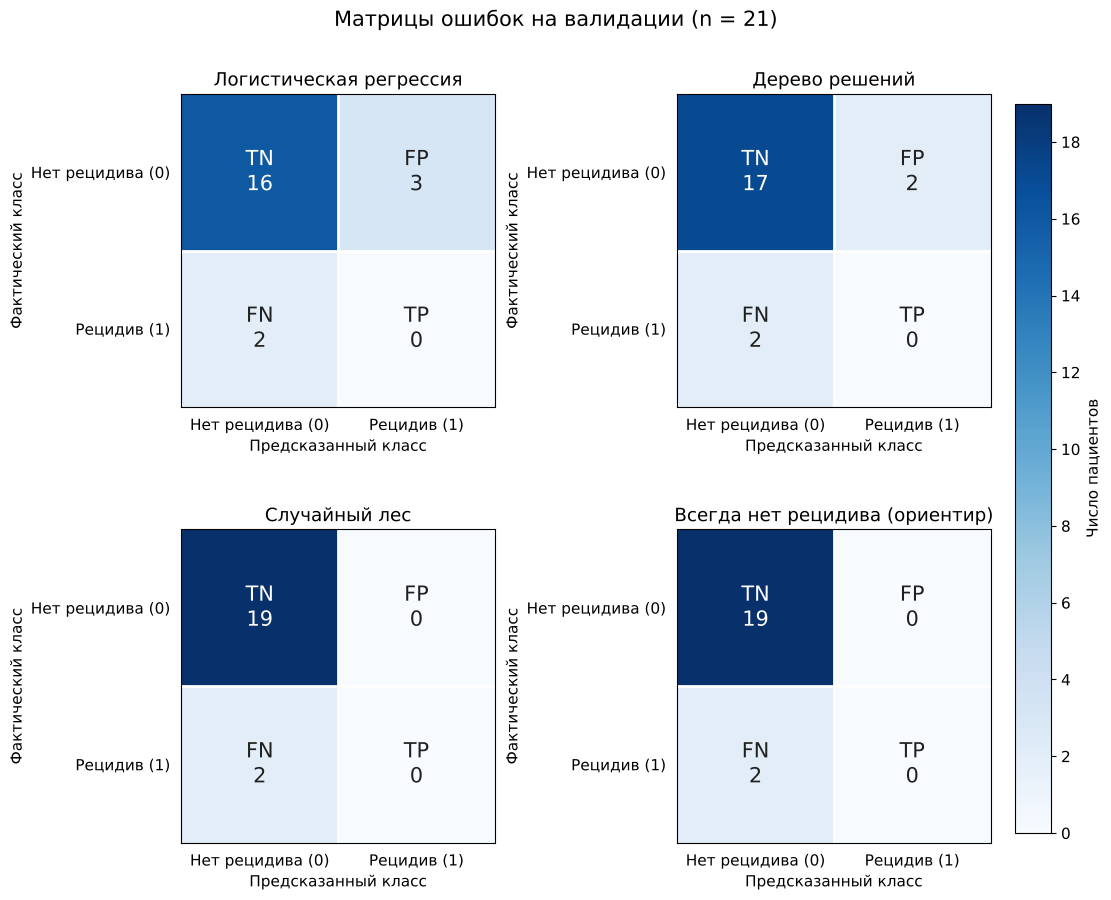

In [9]:
confusion_matrices = {name: confusion_matrix(y_validation, prediction, labels=[0, 1])
                      for name, prediction in validation_predictions.items()}
assert len(confusion_matrices) == 4
assert all(matrix.sum() == len(validation) for matrix in confusion_matrices.values())

fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
class_labels = ["Нет рецидива (0)", "Рецидив (1)"]
cell_labels = np.array([["TN", "FP"], ["FN", "TP"]])
color_max = max(matrix.max() for matrix in confusion_matrices.values())
for ax, (name, matrix) in zip(axes.flat, confusion_matrices.items()):
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=color_max)
    ax.set(title=name, xlabel="Предсказанный класс", ylabel="Фактический класс",
           xticks=[0, 1], yticks=[0, 1], xticklabels=class_labels, yticklabels=class_labels)
    ax.tick_params(axis="both", length=0, pad=8)
    for row in range(2):
        for column in range(2):
            value = matrix[row, column]
            ax.text(column, row, f"{cell_labels[row, column]}\n{value}",
                    ha="center", va="center", fontsize=15,
                    color="white" if value > color_max / 2 else "#202020")
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)

colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.85, pad=0.03)
colorbar.set_label("Число пациентов")
colorbar.set_ticks(np.arange(0, color_max + 1, 2))
fig.suptitle(f"Матрицы ошибок на валидации (n = {len(validation)})", fontsize=15)
fig.savefig("text/fig/confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

fig.set_size_inches(6.4, 6.2)
fig.suptitle("").set_visible(False)
fig.get_layout_engine().set(h_pad=0.18, hspace=0.15, w_pad=0.08, wspace=0.04)
report_names = ["Логистическая\nрегрессия", "Дерево решений", "Случайный лес", "Постоянный\nпрогноз"]
for ax, name in zip(axes.flat, report_names):
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set(xlabel="Прогноз", ylabel="Факт")
    ax.tick_params(axis="both", pad=3)
fig.savefig("text/fig/confusion_matrices_report.pdf", bbox_inches="tight")